# 9 · 3-D recursive search

Notebook 7 split the published search's error by what each scene recorded: on drawn tiles where
only **part** moves - a dragged window, a region scrolling inside a still desktop - the true motion
per 16 px block would take back 68% of it, notebook 4's candidates a quarter; on video, 75%. One
motion per tile cannot move a window without moving the desktop under it, nor follow two things
moving apart in a video.
Notebook 4 tried a motion per block and lost: a block searched on its own matches falsely - a
flat block anywhere, a line of text the line above - and smaller blocks lost more.

TV frame-rate converters met the same problem and solved it without a network: **3-D
recursive search** (de Haan et al., 1993; `helpers/recursive.py`). Per 8×8 block it tries a
handful of candidates - its neighbours' vectors and its own, its own from the pair before,
small updates of them, zero, and seeds given from elsewhere - each costing its mean absolute
luma difference plus a penalty by kind, so a vector new to the neighbourhood wins only where it
matches clearly better. The field stays smooth, and a false match has to beat its neighbours.
Ties go to the seeds before zero - a flat block on a scroll must move with the text around it -
and a block that took the tile's motion carries the tile search's measure of it, so a scroll
stays one motion (both found on a first run, which lost to the tile search on every setting
without them).
Every block updates at once from the pass before, three passes - the form a GPU or an ONNX
graph can run - instead of the original's scan in order.

**Seeds**: the pyramid's motion of the tile (notebook 8), the next two minima of the published
search's cost, and the published search's motion of each 32 px block - notebook 4's
candidates. As a variant, the **pointer's** motion, which the client knows and a dragged window
follows. Vectors are whole pixels while searching, fitted below a pixel at the end, and carried
to N+1 as whole pixels (notebook 8).

**What would count.** Where part of a tile moves, or a video holds several motions, 3DRS has to
beat one motion per tile, and take back a clear share of the error there, without losing on the
rest.

**Measuring is not predicting.** A field that finds a window's motion carries it on; when the
drag stops between N and N+1, that is worse than the tile search, which missed the window and
so repeats it. So beside every score is the same score with the stop decided perfectly per
tile - the better of the method's N+1 and repeat: what the field would be worth beside a stop
decision such as notebook 6's. It sees N+1, so it bounds, it does not predict.

Steps:

1. **A window over a still desktop** - one synthetic tile, the field each method finds.
2. **Tuning on train clips** - the penalties, the block size and the passes, on 36 train clips.
3. **Validation** - every method on the same frames of the 232 validation clips.
4. **By what happened** - notebook 7's families of label.
5. **The error where part of the tile moves** - how much of the search's error each takes back.
6. **One tile** - the fields drawn, where 3DRS gains most and loses most.
7. **Work** - what it costs against the published search.

Needs: `00_data_preprocess.ipynb` and the sources it read. Nothing is trained or exported;
results are cached in `checkpoints/recursive/`.

In [1]:
"""Settings."""

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from helpers import budget, history, models, recursive, runs, show, training
from helpers.recursive import FAMILIES, RecursiveSearch
from helpers.training import DEVICE

STILL, SHARPNESS, CAP = 0.1, 10.0, 50.0
CACHE = training.CHECKPOINT_DIR / "recursive"
SEED = 0
training.seed_everything(SEED)

manifest = training.load_manifest()
training.describe(manifest)
FRACTION = 1 / runs.received_every(manifest)

published = models.TileSearch(4, 2, SHARPNESS, 2, FRACTION, still=STILL).to(DEVICE).eval()
pyramid = models.PyramidSearch(((4, 4, 1), (2, 1, 2), (1, 2, 4)), SHARPNESS, FRACTION, STILL, "equiangular",
                               whole=True).to(DEVICE).eval()
SEEDS = ("tile", "minima", "blocks")


def model(m):
    m = m.to(DEVICE).eval()
    return lambda previous, current, target: m(previous, current)


def blocks(previous, current, target):
    """Notebook 4's 32 px blocks: the published search's costs averaged per block, half carried."""
    return models.warp(current, published.blocks(previous, current, 32))


def oracle(previous, current, target):
    """Notebook 7's motion oracle: per 16 px block, the motion from N to N+1 itself."""
    return models.warp(current, models.Shift(radius=12, block=16).to(DEVICE).field(current, target))


PICTURES = {"repeat": lambda previous, current, target: current,
            "published search": model(models.Motion(search=published, learned=False)),
            "pyramid, whole-pixel (notebook 8)": model(models.Motion(search=pyramid, learned=False)),
            "32 px blocks (notebook 4)": blocks}

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)


## 1. A window over a still desktop

One tile of 328×188, a texture standing still, and a 100×60 window of another texture moved
by (6, −4) px from N−2 to N and by (3, −2) more to N+1. Each method's field over N, the share of
the window's blocks it got right and of the desktop's it left still, and its N+1 (wPSNR).

full search, ±16 px      window blocks right  100%   desktop blocks still  100%   N+1 29.03 dB
3DRS, zero only          window blocks right    0%   desktop blocks still  100%   N+1 26.23 dB
3DRS, tile and minima    window blocks right    0%   desktop blocks still  100%   N+1 24.19 dB
3DRS, + 32 px blocks     window blocks right  100%   desktop blocks still  100%   N+1 33.67 dB
repeat                                                                N+1 25.18 dB


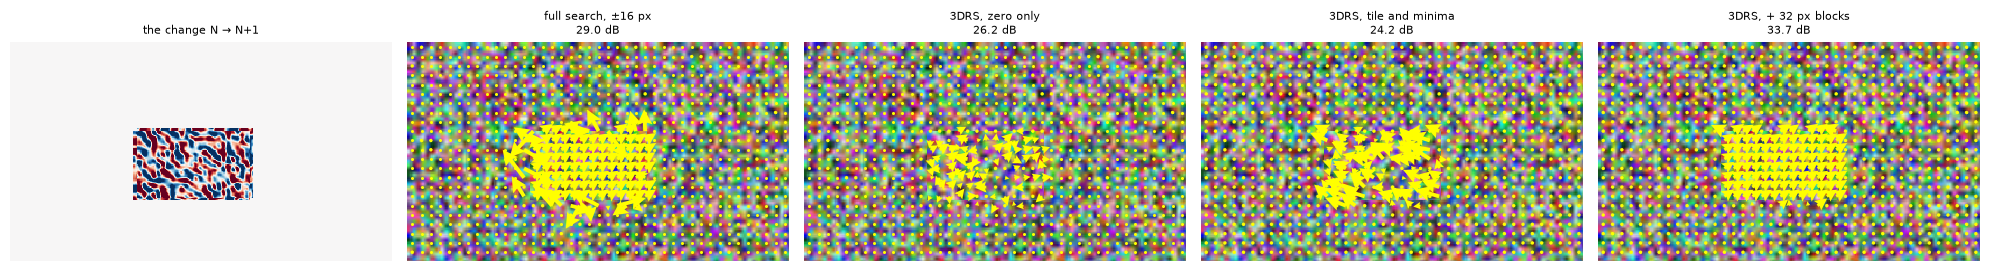

In [2]:
H, W = 188, 328
generator = torch.Generator().manual_seed(SEED)


def texture(h, w):
    small = torch.rand(1, 3, h // 4 + 1, w // 4 + 1, generator=generator)
    return F.interpolate(small, scale_factor=4, mode="bilinear")[..., :h, :w].to(DEVICE)


desktop, window = texture(H, W), texture(60, 100)


def frame(x, y):
    picture = desktop.clone()
    picture[..., y:y + 60, x:x + 100] = window
    return picture


previous, current, target = frame(100, 80), frame(106, 76), frame(109, 74)
order = budget.minima(published.costs(previous, current), 2, 2 * published.radius + 1)
seeds = {"tile": [pyramid.measure(previous, current)[0]],
         "minima": list((-published.table[order] / published.fraction).unbind(1)),
         "blocks": [-published.blocks(previous, current, 32) / published.fraction]}
top = torch.arange(0, H, 8)[:, None]
left = torch.arange(0, W, 8)[None, :]
inside = ((top >= 76) & (top + 8 <= 136) & (left >= 106) & (left + 8 <= 206)).to(DEVICE)
away = ~(((top < 140) & (top + 8 > 76)) & ((left < 206) & (left + 8 > 100))).to(DEVICE)

tried = {"full search, ±16 px": recursive.full_search(previous, current, 8, 16),
         "3DRS, zero only": RecursiveSearch()(previous, current, None, []),
         "3DRS, tile and minima": RecursiveSearch()(previous, current, None, seeds["tile"] + seeds["minima"]),
         "3DRS, + 32 px blocks": RecursiveSearch()(previous, current, None, sum(seeds.values(), []))}
fig, axes = plt.subplots(1, len(tried) + 1, figsize=(4 * (len(tried) + 1), 2.8))
show.change(axes[0], current, target, "the change N → N+1")
for ax, (name, (field, fine)) in zip(axes[1:], tried.items()):
    right = ((field[0, 0] == 6) & (field[0, 1] == -4))[inside].float().mean().item()
    still = (field[0].abs().sum(0) == 0)[away].float().mean().item()
    score = history.sample_wpsnr(recursive.carried(current, fine, 8), target).item()
    print(f"{name:<24} window blocks right {right:5.0%}   desktop blocks still {still:5.0%}   N+1 {score:5.2f} dB")
    show.motion(ax, current, -recursive.per_pixel(fine, H, W, 8)[0], f"{name}\n{score:.1f} dB", every=8, gain=1.5)
print(f"{'repeat':<24} {'':>44} N+1 {history.sample_wpsnr(current, target).item():5.2f} dB")
fig.tight_layout()
plt.show()

## 2. Tuning on train clips

Every 19th train clip (36), the same frames for every setting: the penalties times 0 to 16
(0: every candidate on its cost alone), blocks of 8 and 16 px, and 1 to 4 passes. Scored on the
**moving** tiles (the published gate open) capped at 50 dB, as notebooks 6 and 8 do - raw, and
with the stop decided perfectly. The setting is chosen by the second: what is tuned here is
the measurement, and the stop is notebook 6's to decide.

In [3]:
CACHE.mkdir(parents=True, exist_ok=True)


def cached(name, split, fields, pictures, chosen=None):
    path = CACHE / f"{name}.pkl"
    names = set(fields) | set(pictures)
    if path.exists() and path.stat().st_mtime > (training.DATA_DIR / "manifest.json").stat().st_mtime:
        found = pickle.loads(path.read_bytes())
        if set(found["wpsnr"]) == names:
            return found
    started = time.time()

    def progress(count, index):
        if (count + 1) % 20 == 0:
            print(f"{count + 1} clips, {time.time() - started:.0f}s", flush=True)

    found = recursive.load(manifest, split, fields, pictures, published, pyramid, STILL, chosen=chosen,
                           progress=progress)
    print(f"{len(found['tiles']['source'])} tiles in {time.time() - started:.0f}s")
    path.write_bytes(pickle.dumps(found))
    return found


def capped(found, name):
    return np.minimum(found["wpsnr"][name], CAP)


def stopped(found, name):
    """Each tile's score with the stop decided perfectly: the better of the method's N+1 and repeat."""
    return np.maximum(capped(found, name), capped(found, "repeat"))


SWEEP = {f"{block} px, penalties x{scale:g}, 3 passes": RecursiveSearch(block, 3, scale, seeds=SEEDS)
         for block in (8, 16) for scale in (0, 0.5, 1, 2, 4, 8, 16)}
SWEEP |= {f"8 px, penalties x1, {passes} passes": RecursiveSearch(8, passes, 1, seeds=SEEDS) for passes in (1, 2, 4)}
TRAIN_CLIPS = list(range(0, len(manifest["splits"]["train"]["sources"]), 19))
sweep = cached("train_sweep", "train", SWEEP, {k: PICTURES[k] for k in ("repeat", "published search")}, TRAIN_CLIPS)
tiles = sweep["tiles"]
moving, part = tiles["moving"], tiles["moving"] & (tiles["family"] == "part of the tile moves")
print(f"{moving.sum()} moving tiles, {part.sum()} where part moves\n")
print(f"{'moving tiles, ≤ 50 dB':<34}{'raw':>8}{'perfect stop':>14}{'part moves':>12}{'part, perfect stop':>20}")
for name in ["repeat", "published search", *SWEEP]:
    print(f"{name:<34}{capped(sweep, name)[moving].mean():8.2f}{stopped(sweep, name)[moving].mean():14.2f}"
          f"{capped(sweep, name)[part].mean():12.2f}{stopped(sweep, name)[part].mean():20.2f}")
BEST_NAME = max(SWEEP, key=lambda name: stopped(sweep, name)[moving].mean())
best = SWEEP[BEST_NAME]
print(f"\nchosen: {BEST_NAME}")

20 clips, 100s
2957 tiles in 169s
1834 moving tiles, 79 where part moves

moving tiles, ≤ 50 dB                  raw  perfect stop  part moves  part, perfect stop
repeat                               36.75         36.75       37.60               37.60
published search                     37.91         38.46       35.85               37.79
8 px, penalties x0, 3 passes         37.57         38.66       35.18               38.30
8 px, penalties x0.5, 3 passes       37.61         38.67       35.21               38.33
8 px, penalties x1, 3 passes         37.62         38.67       35.22               38.33
8 px, penalties x2, 3 passes         37.65         38.68       35.23               38.33
8 px, penalties x4, 3 passes         37.68         38.68       35.24               38.33
8 px, penalties x8, 3 passes         37.72         38.69       35.25               38.34
8 px, penalties x16, 3 passes        37.76         38.70       35.24               38.33
16 px, penalties x0, 3 passes       

## 3. Validation

All 232 validation clips rebuilt once, every method on the same frames (x264 does not encode a
clip the same way twice), every tile at every received frame N from 6 on - notebook 8's tiles.
Beside the chosen 3DRS: without its memory of the pair before (temporal candidates), with only
the tile-wide seeds, with the pointer's motion as a seed, carried by reading each pixel's
vector where its content was in N (`project`), and with the other block size; the full search
per 8 px block within ±16 px as the control, and notebook 7's motion oracle as the ceiling.

Columns as in notebook 8: the changed tiles (N+1 differs from N), all, the moving ones capped
at 50 dB with the gain over the published search and its 95% range over clips - and the moving
ones with the stop decided perfectly.

In [4]:
def variant(**changes):
    settings = dict(block=best.block, passes=best.passes, scale=best.scale, seeds=SEEDS) | changes
    return RecursiveSearch(**settings)


OTHER = 16 if best.block == 8 else 8
FIELDS = {"full search, 8 px, ±16 px": ("full", 8, 16),
          "3DRS": best,
          "3DRS, no temporal": variant(temporal=False),
          "3DRS, tile seeds only": variant(seeds=("tile", "minima")),
          "3DRS + pointer": variant(seeds=SEEDS + ("pointer",)),
          "3DRS, projected carry": variant(project=True),
          f"3DRS, {OTHER} px blocks": variant(block=OTHER)}
val = cached("val", "val", FIELDS, PICTURES | {"motion oracle (notebook 7)": oracle})
tiles = val["tiles"]
moving, changed, clip_of = tiles["moving"], tiles["changed"], tiles["source"]
ORDER = ["repeat", "published search", "pyramid, whole-pixel (notebook 8)", "32 px blocks (notebook 4)", *FIELDS,
         "motion oracle (notebook 7)"]
BASE = "published search"
rng = np.random.default_rng(SEED)


def over_clips(gain, mask, draws=2000):
    """The 95% range of the mean of `gain` over `mask`, clips drawn with replacement."""
    per = [gain[mask & (clip_of == c)] for c in np.unique(clip_of[mask])]
    means = [np.concatenate([per[i] for i in rng.integers(0, len(per), len(per))]).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])


print(f"{len(moving)} tiles from {len(set(clip_of))} clips: {moving.sum()} moving, {changed.sum()} changed\n")
print(f"{'wPSNR (dB)':<36}{'changed':>16}{'all':>16}{'moving, ≤ 50 dB':>18}{'95% over clips':>18}{'perfect stop':>14}")
for name in ORDER:
    s, base = val["wpsnr"][name], val["wpsnr"][BASE]
    gain = capped(val, name) - capped(val, BASE)
    low, high = over_clips(gain, moving) if name != BASE else (0, 0)
    print(f"{name:<36}{s[changed].mean():8.2f} ({s[changed].mean() - base[changed].mean():+5.2f})"
          f"{s.mean():8.2f} ({s.mean() - base.mean():+5.2f})"
          f"{capped(val, name)[moving].mean():10.2f} ({gain[moving].mean():+5.2f})  [{low:+.2f}, {high:+.2f}]"
          f"{stopped(val, name)[moving].mean():14.2f}")

20 clips, 132s
40 clips, 258s
60 clips, 371s
80 clips, 493s
100 clips, 575s
120 clips, 680s
140 clips, 769s
160 clips, 853s
180 clips, 940s
200 clips, 1031s
220 clips, 1118s
17190 tiles in 1171s
17190 tiles from 232 clips: 9088 moving, 5559 changed

wPSNR (dB)                                   changed             all   moving, ≤ 50 dB    95% over clips  perfect stop
repeat                                 28.36 (-3.12)   61.29 (-0.56)     36.66 (-1.44)  [-2.19, -0.79]         36.66
published search                       31.48 (+0.00)   61.84 (+0.00)     38.10 (+0.00)  [+0.00, +0.00]         38.74
pyramid, whole-pixel (notebook 8)      31.41 (-0.07)   61.92 (+0.08)     38.01 (-0.09)  [-0.23, +0.05]         38.68
32 px blocks (notebook 4)              30.89 (-0.59)   60.67 (-1.17)     37.30 (-0.81)  [-1.08, -0.53]         38.77
full search, 8 px, ±16 px              30.01 (-1.48)   60.36 (-1.48)     36.43 (-1.68)  [-2.02, -1.36]         38.46
3DRS                                   31.81 (

## 4. By what happened

The moving tiles by notebook 7's families of label - raw, then with the stop decided perfectly
- and the tiles where part moves by label.

In [5]:
family, labels = tiles["family"], tiles["label"]
for title, score in (("moving, ≤ 50 dB", capped), ("moving, ≤ 50 dB, perfect stop", stopped)):
    print(f"{title:<36}" + "".join(f"{name:>24}" for name in FAMILIES))
    print(f"{'tiles':<36}" + "".join(f"{(moving & (family == f)).sum():24}" for f in FAMILIES))
    for name in ORDER:
        print(f"{name:<36}" + "".join(f"{score(val, name)[moving & (family == f)].mean():24.2f}" for f in FAMILIES))
    print()

shown = [label for label in budget.LABELS if label.startswith(("drag", "region")) and not label.endswith("starts")
         and (moving & (labels == label)).sum() >= 10]
print(f"{'part moves, ≤ 50 dB (raw)':<36}" + "".join(f"{label:>24}" for label in shown))
print(f"{'tiles':<36}" + "".join(f"{(moving & (labels == label)).sum():24}" for label in shown))
for name in ORDER:
    print(f"{name:<36}" + "".join(f"{capped(val, name)[moving & (labels == label)].mean():24.2f}" for label in shown))

moving, ≤ 50 dB                             whole tile moves  part of the tile moves             unannounced                  screen                   video                   other
tiles                                                   1785                     618                      85                    4003                    1830                     767
repeat                                                 25.34                   29.14                   23.24                   42.04                   33.95                   48.93
published search                                       30.69                   30.15                   23.05                   42.68                   34.18                   48.89
pyramid, whole-pixel (notebook 8)                      30.67                   30.20                   23.03                   42.45                   34.24                   48.89
32 px blocks (notebook 4)                              28.72                   28.89           

## 5. The error where part of the tile moves

Notebook 7's budget: the weighted squared error summed over the kept region, which adds up
across tiles, on the **active** tiles (the gate open, or N+1 differs from N). Per family, the
share of the published search's error each method takes back - raw, and with the stop decided
perfectly per tile. Notebook 7 had the motion oracle take back 68% where part of a drawn tile moves, 75% on video.

In [6]:
active = moving | changed
error = val["error"]
base = error[BASE]
print(f"{'taken back of the search error':<36}" + "".join(f"{name:>24}" for name in FAMILIES))
print(f"{'share of the search error':<36}" + "".join(f"{base[active & (family == f)].sum() / base[active].sum():24.1%}"
                                                     for f in FAMILIES))
for title, pick in (("raw", lambda name: error[name]),
                    ("perfect stop", lambda name: np.minimum(error[name], error["repeat"]))):
    print(f"\n{title}")
    for name in ORDER:
        print(f"{name:<36}" + "".join(f"{1 - pick(name)[active & (family == f)].sum() / base[active & (family == f)].sum():24.1%}"
                                      for f in FAMILIES))

taken back of the search error              whole tile moves  part of the tile moves             unannounced                  screen                   video                   other
share of the search error                              33.2%                    9.6%                    6.0%                   35.8%                   15.2%                    0.1%

raw
repeat                                               -113.8%                  -50.6%                    0.9%                   -5.8%                  -16.7%                   49.5%
published search                                        0.0%                    0.0%                    0.0%                    0.0%                    0.0%                    0.0%
pyramid, whole-pixel (notebook 8)                       2.5%                   -2.3%                   -0.5%                    1.4%                   -2.2%                    0.0%
32 px blocks (notebook 4)                             -12.3%                   -6.0%      

## 6. One tile

Among the moving tiles where part moves and the motion goes on, the one where 3DRS gains most
over the published search and the one where it loses most - rebuilt, so the codec's pictures
differ from the scored ones by a level or so. Each row: the change N → N+1, then N with the
motion each found (arrows: where the content goes, 1.5 times its length), and below, each
one's error against N+1.

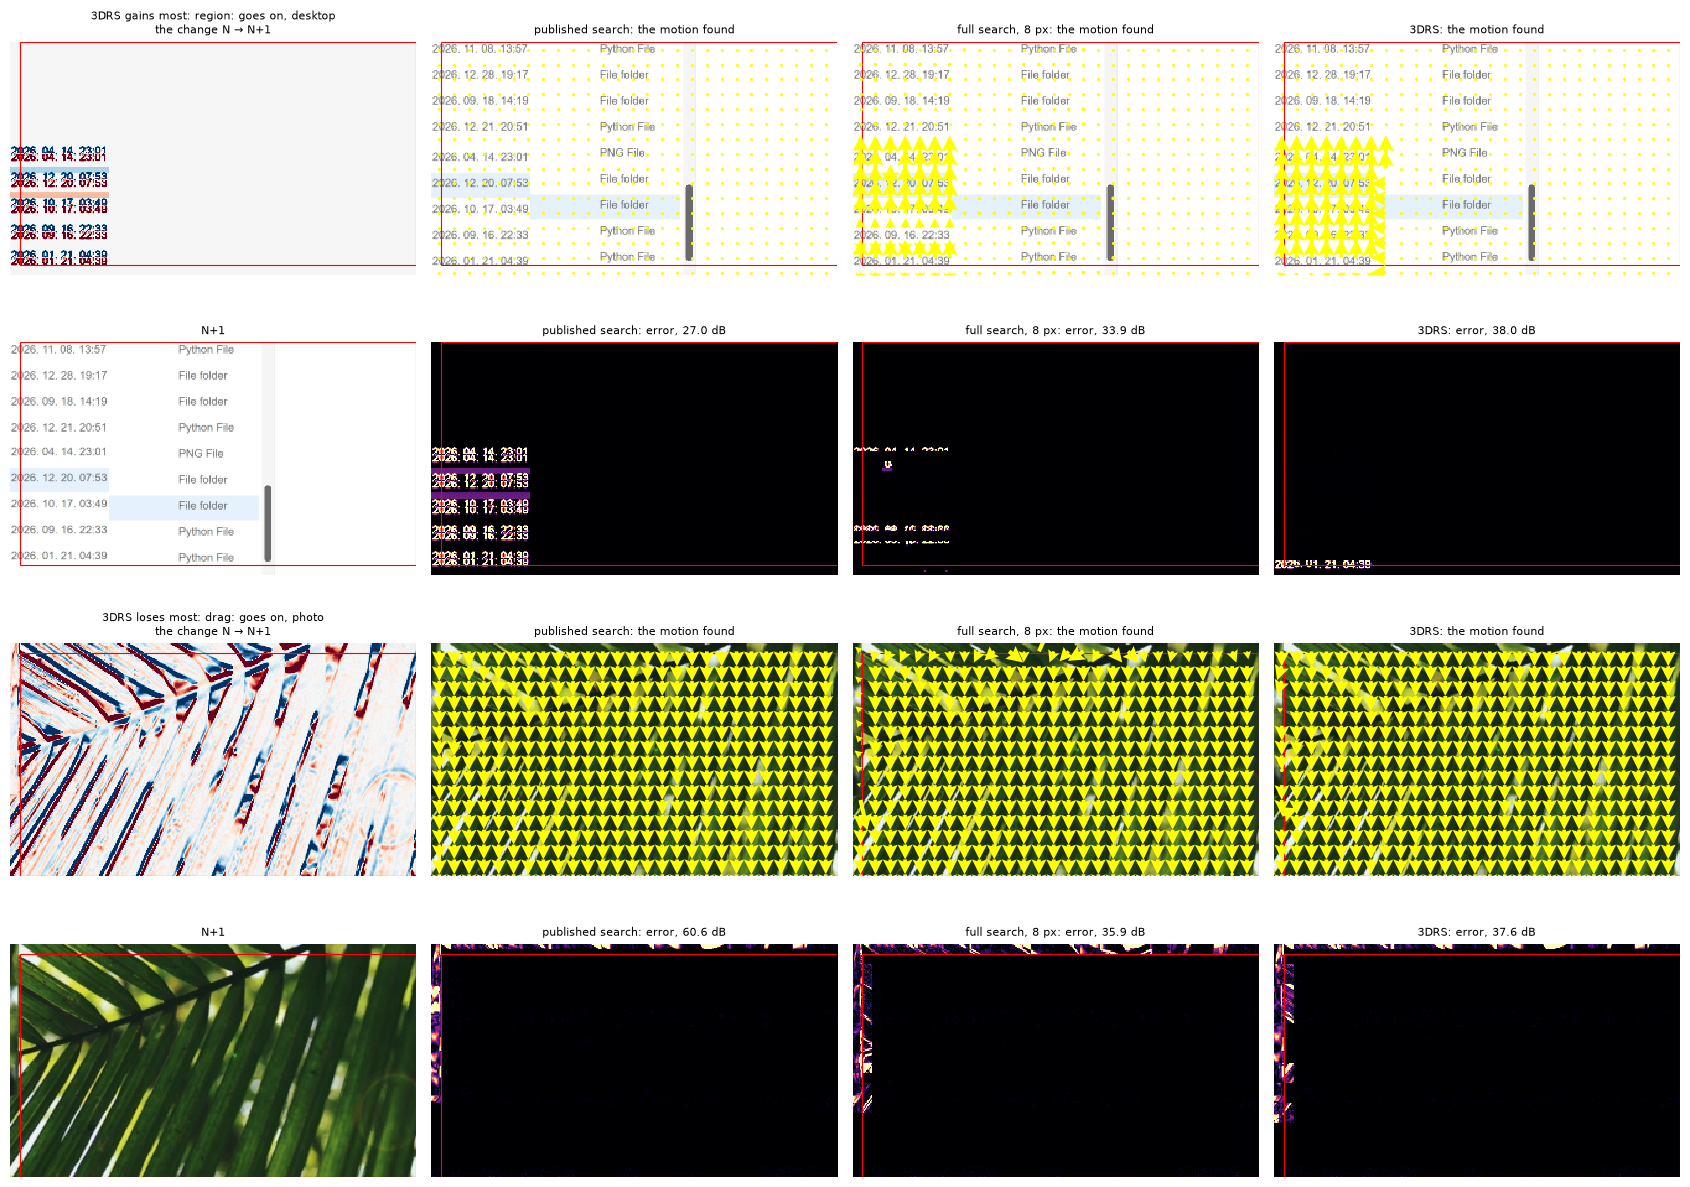

In [7]:
steady = moving & np.isin(labels, ["drag: goes on", "region: goes on"])
gain = val["wpsnr"]["3DRS"] - val["wpsnr"][BASE]
picks = {"3DRS gains most": np.flatnonzero(steady)[gain[steady].argmax()],
         "3DRS loses most": np.flatnonzero(steady)[gain[steady].argmin()]}
fig, axes = plt.subplots(2 * len(picks), 4, figsize=(17, 6.2 * len(picks)))
for row, (title, i) in enumerate(picks.items()):
    source = manifest["splits"]["val"]["sources"][tiles["source"][i]]
    clip = recursive.Clip(source, manifest, published, pyramid)
    p, t = clip.ends.index(tiles["frame"][i]), tiles["tile"][i]
    previous, current, target = clip.windows([p], (-1, 0, 1))[t:t + 1].unbind(1)
    box = tuple(tiles["box"][i])
    tracked = clip.track(best)[p, t:t + 1] * float(clip.still[p, t] >= STILL)
    full = recursive.full_search(previous, current, 8, 16)[1] * float(clip.still[p, t] >= STILL)
    made = {"published search": models.Motion(search=published, learned=False)(previous, current),
            "full search, 8 px": recursive.carried(current, full, 8),
            "3DRS": recursive.carried(current, tracked, best.block)}
    motions = {"published search": published(previous, current).expand(-1, -1, *current.shape[-2:]) / FRACTION,
               "full search, 8 px": -recursive.per_pixel(full, *current.shape[-2:], 8),
               "3DRS": -recursive.per_pixel(tracked, *current.shape[-2:], best.block)}
    top, bottom = axes[2 * row], axes[2 * row + 1]
    show.change(top[0], current, target, f"{title}: {labels[i]}, {source['kind']}\nthe change N → N+1", box)
    show.picture(bottom[0], target, "N+1", box)
    for k, name in enumerate(made):
        score = history.sample_wpsnr(*(x[..., box[0]:box[0] + box[2], box[1]:box[1] + box[3]] for x in (made[name], target))).item()
        show.motion(top[k + 1], current, motions[name][0], f"{name}: the motion found", box, every=12, gain=1.5)
        show.error(bottom[k + 1], made[name], target, f"{name}: error, {score:.1f} dB", box)
fig.tight_layout()
plt.show()

## 7. Work

Luma differences a tile, as notebook 8 counts them: the published search samples a quarter of
the resolution's positions times 81 offsets; 3DRS tries every candidate on every pixel of the
tile - its first choice among the fixed candidates, then per pass the block's own vector, four
neighbours, three updates and the fixed ones again, and five for the fit below a pixel - and
needs the seeds besides (the pyramid and the published search's costs). And the time in torch
on this GPU for one 1080p frame's 36 tiles - a ratio, not a browser time.

In [8]:
height, width = 188, 328


def search_work(levels):
    total = 0
    for scale, radius, stride in levels:
        positions = len(range(0, height // scale - 2 * radius, stride)) * len(range(0, width // scale - 2 * radius, stride))
        total += positions * (2 * radius + 1) ** 2
    return total


published_work = search_work([(2, 4, 2)])
pyramid_work = search_work(pyramid.levels)
fixed = 1 + 1 + 2 + 1 + 1                      # zero, tile, two minima, 32 px blocks, the pair before
candidates = fixed + best.passes * (8 + fixed) + 5
recursive_work = candidates * height * width
print(f"published search   {published_work / 1e6:6.2f} M differences a tile")
print(f"pyramid            {pyramid_work / 1e6:6.2f} M")
print(f"3DRS               {recursive_work / 1e6:6.2f} M ({candidates} candidates a pixel) + both seeds: "
      f"{(recursive_work + published_work + pyramid_work) / published_work:.1f}x the published search")
print(f"full search ±16    {33 * 33 * height * width / 1e6:6.2f} M")

frames = torch.rand(36, 2, 3, height, width, device=DEVICE)
previous, current = frames.unbind(1)
seeds = [pyramid.measure(previous, current)[0], *(-published.table[budget.minima(published.costs(previous, current), 2, 9)]
                                                 / published.fraction).unbind(1),
         -published.blocks(previous, current, 32) / published.fraction]
last = best(previous, current, None, seeds)[0]


def timed(run, repeats=20):
    run()
    torch.cuda.synchronize()
    started = time.perf_counter()
    for _ in range(repeats):
        run()
    torch.cuda.synchronize()
    return (time.perf_counter() - started) / repeats * 1000


with torch.no_grad():
    times = {"published search": timed(lambda: models.Motion(search=published, learned=False)(previous, current)),
             "pyramid": timed(lambda: pyramid.measure(previous, current)),
             "3DRS, seeds given": timed(lambda: best(previous, current, last, seeds))}
for name, ms in times.items():
    print(f"{name:<20} {ms:6.2f} ms for 36 tiles in torch ({ms / times['published search']:.1f}x)")

published search     0.27 M differences a tile
pyramid              0.36 M
3DRS                 3.27 M (53 candidates a pixel) + both seeds: 14.4x the published search
full search ±16     67.15 M
published search       2.02 ms for 36 tiles in torch (1.0x)
pyramid                3.72 ms for 36 tiles in torch (1.8x)
3DRS, seeds given     40.22 ms for 36 tiles in torch (19.9x)


## What it says

- **On the whole set 3DRS ties the tile search, and costs 14 times as much.** On the moving
  validation tiles +0.03 dB (95% over clips −0.20 to +0.25), on the changed tiles +0.33; with the
  stop decided perfectly 39.10 dB against the search's 38.74. Its tuning hardly matters: from no
  penalties to 16 times, within 0.1 dB.
- **It wins on the recordings and loses on the drawn scenes.** Video +0.42 dB on the moving tiles
  (it takes back 18% of the search's error there), screens +0.24 (4%) - several motions in a tile,
  and parts that move against a still rest. On drawn tiles that move whole it loses 0.46, and on
  those that move in part 0.80: it finds the dragged window or the scrolled region the tile
  search misses, and carries it past the frame it stops.
- **Smoothness is what makes a motion per block usable at all.** The same blocks searched
  exhaustively lose 1.68 dB, notebook 4's 32 px blocks 0.81, 3DRS ties - the candidates and their
  penalties are the difference. Blocks of 16 px beat 8 (+0.03 against −0.19).
- **Memory adds nothing, nor does reading the vector where the content came from; the pointer
  helps the drags.** Without the pair before +0.04, carried by `project` +0.04, the tile-wide seeds
  alone +0.07; with the pointer's motion as a seed it takes back 10% of the error where part of a
  drawn tile moves, against 1%.
- **It costs an order of magnitude more**: 53 candidates a pixel - 3.27 M luma differences a tile
  against 0.27 M, 14 times with the searches it is seeded by; in this torch form 40 ms for 36 tiles
  against 2.0 ms.

So a motion per block is worth a few tenths of a dB on recorded video and screens, where a tile
holds more than one motion, and loses where a drawn motion stops; overall it ties one motion per
tile, at fourteen times the work. With a stop decision per block it would be ahead (+0.36 with a
perfect one) - which the frames, again, do not announce.